# UJIAN TENGAH SEMESTER – MACHINE LEARNING
## Prediksi Jumlah Penyewaan Sepeda (Bike Sharing) – Jalur B: Regresi

**Nama:** ADITHA DIVA ANGGASWARA  
**NIM:** 2301010329  
**SEED:** 329  
**Mata kuliah:** Machine Learning

Notebook ini mengikuti alur CRISP-DM dan ketentuan UTS. Jalankan seluruh sel dari atas ke bawah (*Runtime → Run all*). Hasil metrik dan keputusan akhir akan dihitung dari data yang benar-benar dijalankan, bukan angka perkiraan.

## 1. Business Understanding – Pemahaman Masalah

### Latar belakang dan tujuan
Layanan penyewaan sepeda perlu memperkirakan jumlah sepeda yang akan disewa pada suatu jam berdasarkan informasi kalender, waktu, dan kondisi cuaca. Proyek ini membangun model regresi untuk memprediksi `cnt` (total penyewaan sepeda per jam).

### Pengguna dan keputusan
Hasil analisis dapat membantu pengelola layanan bike sharing dalam merencanakan ketersediaan sepeda, redistribusi sepeda antarstasiun, dan kebutuhan operasional pada jam sibuk. Prediksi bukan keputusan otomatis; pengelola tetap perlu mempertimbangkan kondisi lapangan.

### Dataset dan sumber
- Dataset: **Bike Sharing Dataset – Hour**
- Sumber resmi: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/275/bike-sharing-dataset)
- DOI: `10.24432/C5W894`
- Lisensi: **CC BY 4.0** (cantumkan atribusi sumber saat menggunakan/membagikan data).
- Tanggal akses: **26 November 2026**
- Periode data: tahun 2011–2012, Capital Bikeshare, Washington D.C.

Target adalah `cnt`. Kolom `casual` dan `registered` tidak dipakai sebagai fitur karena `cnt = casual + registered`; memasukkannya akan menyebabkan *target leakage*. `instant` juga tidak digunakan sebagai prediktor karena hanya nomor indeks.

### Kamus data (data dictionary)

| Kolom | Tipe | Arti | Satuan/keterangan |
|---|---|---|---|
| instant | Integer | Nomor indeks rekaman | Indeks |
| dteday | Tanggal | Tanggal pencatatan | YYYY-MM-DD |
| season | Kategori berkode | Musim (1–4) | Kode kategori |
| yr | Kategori berkode | Tahun (0=2011, 1=2012) | Kode kategori |
| mnth | Kategori berkode | Bulan (1–12) | Kode kategori |
| hr | Kategori berkode | Jam dalam sehari (0–23) | Jam |
| holiday | Kategori biner | Hari libur atau bukan | 0/1 |
| weekday | Kategori berkode | Hari dalam minggu | 0–6 |
| workingday | Kategori biner | Hari kerja atau bukan | 0/1 |
| weathersit | Kategori berkode | Kategori kondisi cuaca | Kode kategori |
| temp | Numerik | Suhu ternormalisasi | Skala 0–1 |
| atemp | Numerik | Suhu terasa ternormalisasi | Skala 0–1 |
| hum | Numerik | Kelembapan ternormalisasi | Skala 0–1 |
| windspeed | Numerik | Kecepatan angin ternormalisasi | Skala 0–1 |
| casual | Integer | Penyewaan pengguna kasual | Sepeda/jam |
| registered | Integer | Penyewaan pengguna terdaftar | Sepeda/jam |
| cnt | Integer | Total penyewaan (target) | Sepeda/jam |

Satuan untuk `temp`, `atemp`, `hum`, dan `windspeed` mengikuti skala ternormalisasi pada dataset, bukan satuan fisik langsung.

### Keputusan saya
Saya memilih Jalur B karena target `cnt` berupa angka kontinu/non-negatif. Prediksi jumlah penyewaan dapat membantu perencanaan operasional. Dataset memiliki jauh lebih dari 200 baris dan lebih dari 4 fitur. Kolom `casual` dan `registered` dikeluarkan agar model tidak memperoleh informasi yang secara langsung membentuk target.

## 2. Data Understanding & Exploratory Data Analysis (EDA)
Pada tahap ini data diunduh, diperiksa struktur dan kualitasnya, lalu divisualisasikan. Tiga grafik utama berikut mencakup distribusi target, distribusi fitur, serta hubungan fitur dengan target.

In [1]:
import sys, subprocess, importlib.util
packages = ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn"]
for package in packages:
    module = "sklearn" if package == "scikit-learn" else package
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from urllib.request import urlretrieve
from zipfile import ZipFile
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

SEED = 329
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
zip_path = DATA_DIR / "bike-sharing-dataset.zip"
csv_path = DATA_DIR / "hour.csv"

if not csv_path.exists():
    urlretrieve("https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip", zip_path)
    with ZipFile(zip_path, "r") as z:
        z.extract("hour.csv", DATA_DIR)

df = pd.read_csv(csv_path)
print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head())

Ukuran dataset (baris, kolom): (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:
print("Informasi struktur:")
df.info()
print("\\nTipe data:")
display(df.dtypes.rename("dtype").to_frame())
print("\\nStatistik deskriptif:")
display(df.describe(include="all").T)
print("\\nMissing value per kolom:")
display(df.isna().sum().to_frame("missing"))
print("\\nJumlah baris duplikat:", df.duplicated().sum())

Informasi struktur:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB
\nTipe data:


,dtype
instant,int64
dteday,object
season,int64
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64


\nStatistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,17379.0,NaN,NaN,NaN,8690.0,5017.0295,1.0,4345.5,8690.0,13034.5,17379.0
dteday,17379,731,2012-12-31,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,17379.0,NaN,NaN,NaN,2.50164,1.106918,1.0,2.0,3.0,3.0,4.0
yr,17379.0,NaN,NaN,NaN,0.502561,0.500008,0.0,0.0,1.0,1.0,1.0
mnth,17379.0,NaN,NaN,NaN,6.537775,3.438776,1.0,4.0,7.0,10.0,12.0
hr,17379.0,NaN,NaN,NaN,11.546752,6.914405,0.0,6.0,12.0,18.0,23.0
holiday,17379.0,NaN,NaN,NaN,0.02877,0.167165,0.0,0.0,0.0,0.0,1.0
weekday,17379.0,NaN,NaN,NaN,3.003683,2.005771,0.0,1.0,3.0,5.0,6.0
workingday,17379.0,NaN,NaN,NaN,0.682721,0.465431,0.0,0.0,1.0,1.0,1.0
weathersit,17379.0,NaN,NaN,NaN,1.425283,0.639357,1.0,1.0,1.0,2.0,4.0


\nMissing value per kolom:


,missing
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


\nJumlah baris duplikat: 0


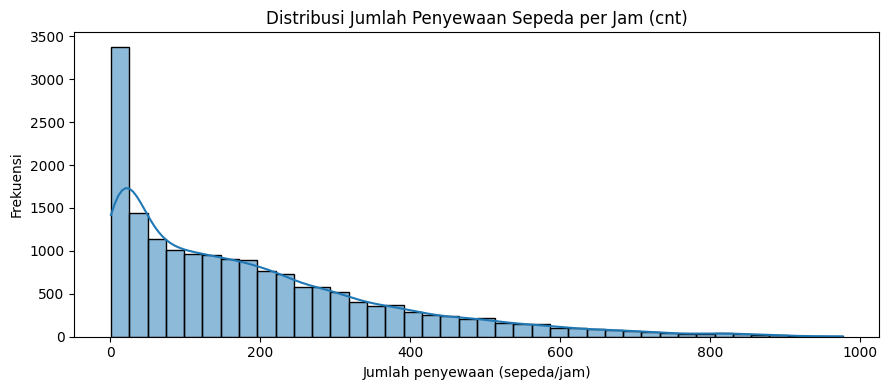

Interpretasi: rata-rata cnt = 189.46, median = 142.00, skewness = 1.28.
Bentuk distribusi dan kemencengannya membantu memahami apakah banyak jam sepi atau jam dengan permintaan tinggi.


In [3]:
# Grafik 1 – Distribusi target
plt.figure(figsize=(9, 4))
sns.histplot(df["cnt"], bins=40, kde=True)
plt.title("Distribusi Jumlah Penyewaan Sepeda per Jam (cnt)")
plt.xlabel("Jumlah penyewaan (sepeda/jam)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

skew_cnt = df["cnt"].skew()
print(f"Interpretasi: rata-rata cnt = {df['cnt'].mean():.2f}, median = {df['cnt'].median():.2f}, skewness = {skew_cnt:.2f}.")
print("Bentuk distribusi dan kemencengannya membantu memahami apakah banyak jam sepi atau jam dengan permintaan tinggi.")

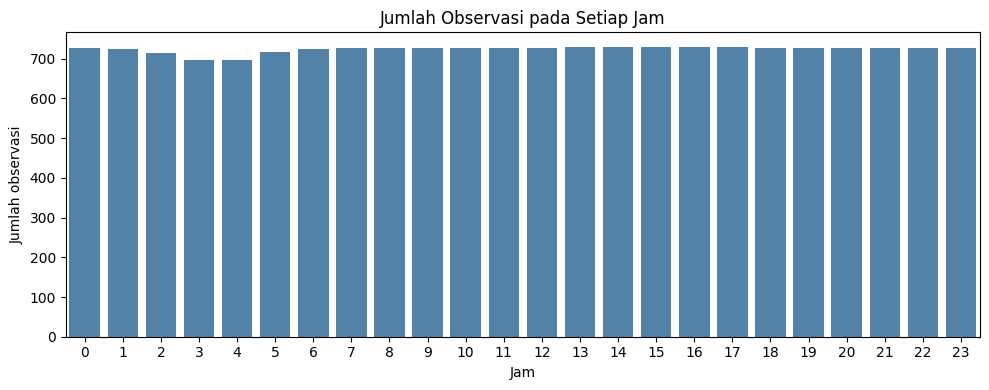

Interpretasi: setiap jam diamati berulang sepanjang periode data; grafik ini menunjukkan cakupan observasi per jam, bukan besarnya permintaan.


In [4]:
# Grafik 2 – Distribusi fitur jam
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="hr", color="steelblue")
plt.title("Jumlah Observasi pada Setiap Jam")
plt.xlabel("Jam")
plt.ylabel("Jumlah observasi")
plt.tight_layout()
plt.show()
print("Interpretasi: setiap jam diamati berulang sepanjang periode data; grafik ini menunjukkan cakupan observasi per jam, bukan besarnya permintaan.")

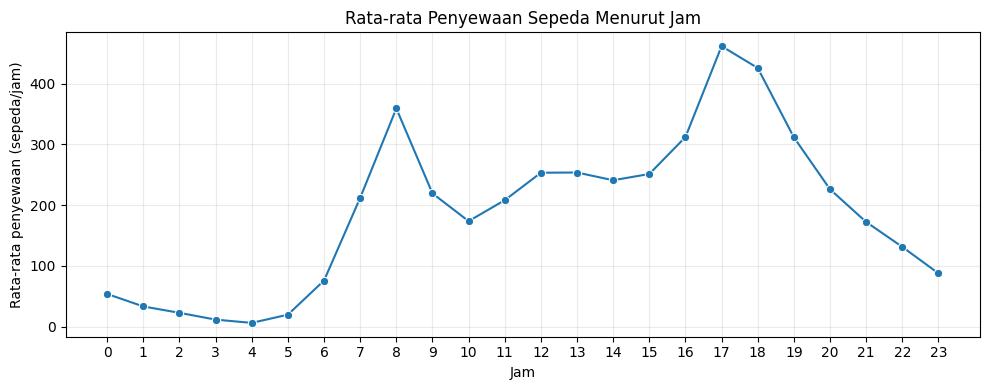

Interpretasi: rata-rata penyewaan tertinggi terjadi pada jam 17, sedangkan terendah pada jam 4.


In [5]:
# Grafik 3 – Hubungan jam dan jumlah penyewaan
hour_mean = df.groupby("hr", as_index=False)["cnt"].mean()
plt.figure(figsize=(10, 4))
sns.lineplot(data=hour_mean, x="hr", y="cnt", marker="o")
plt.title("Rata-rata Penyewaan Sepeda Menurut Jam")
plt.xlabel("Jam")
plt.ylabel("Rata-rata penyewaan (sepeda/jam)")
plt.xticks(range(24))
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()
peak_hour = int(hour_mean.loc[hour_mean["cnt"].idxmax(), "hr"])
low_hour = int(hour_mean.loc[hour_mean["cnt"].idxmin(), "hr"])
print(f"Interpretasi: rata-rata penyewaan tertinggi terjadi pada jam {peak_hour}, sedangkan terendah pada jam {low_hour}.")

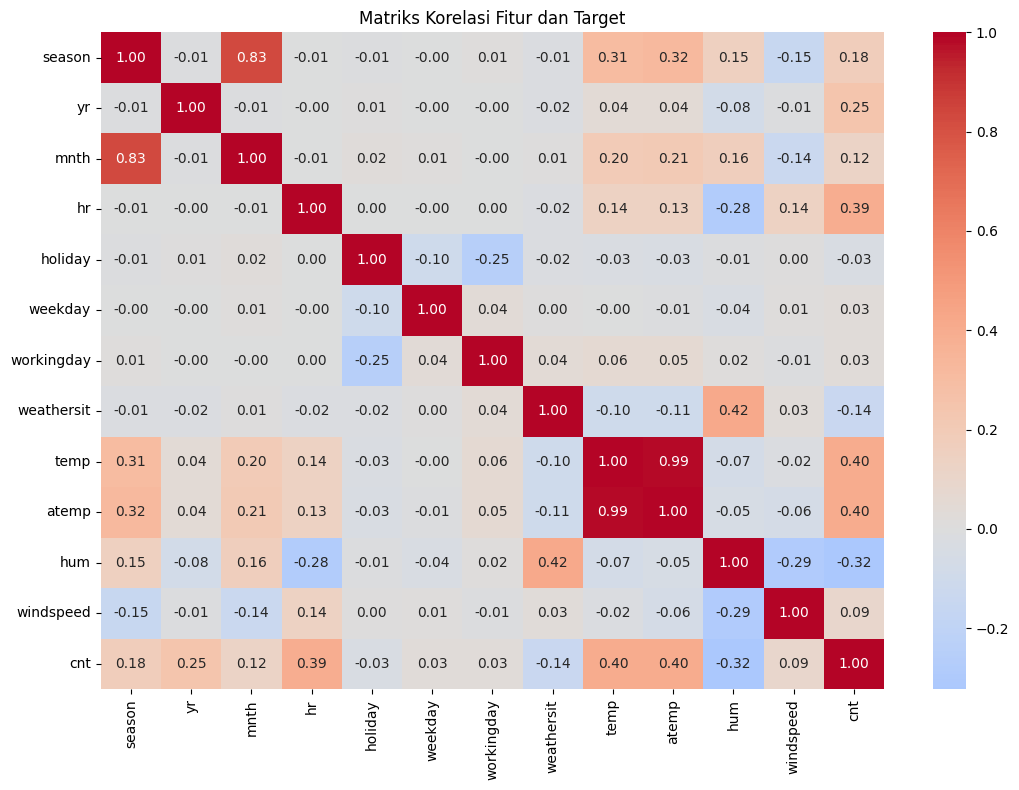

In [6]:
# Grafik tambahan – korelasi numerik untuk mendukung pemilihan fitur sederhana
numeric_for_corr = ["season","yr","mnth","hr","holiday","weekday","workingday","weathersit",
                    "temp","atemp","hum","windspeed","cnt"]
plt.figure(figsize=(11, 8))
sns.heatmap(df[numeric_for_corr].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Matriks Korelasi Fitur dan Target")
plt.tight_layout()
plt.show()

### Keputusan saya
Saya memeriksa ukuran data, tipe kolom, statistik deskriptif, missing value, dan duplikasi. Grafik distribusi target menunjukkan karakter sebaran jumlah penyewaan; distribusi jam memastikan cakupan pengamatan; grafik jam terhadap `cnt` memperlihatkan pola permintaan harian. Korelasi hanya dipakai sebagai petunjuk eksplorasi, bukan bukti sebab-akibat.

## 3. Data Preparation – Pra-pemrosesan Data
Pemisahan data latih dan uji dilakukan **sebelum** proses imputasi/encoding/scaling di-fit. Transformasi dipelajari hanya dari data latih melalui `Pipeline` dan `ColumnTransformer` untuk mencegah data leakage.

In [7]:
# Kolom yang tidak digunakan sebagai prediktor:
# instant = indeks; dteday = tanggal mentah; casual & registered = pembentuk langsung cnt.
TARGET = "cnt"
categorical_features = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]
numeric_features = ["temp", "atemp", "hum", "windspeed"]
feature_columns = categorical_features + numeric_features

X = df[feature_columns].copy()
y = df[TARGET].copy()

# Pemeriksaan kualitas sebelum split
print("Missing value fitur:", int(X.isna().sum().sum()))
print("Missing value target:", int(y.isna().sum()))
print("Duplikat penuh:", int(df.duplicated().sum()))

from sklearn.model_selection import train_test_split, KFold, cross_validate
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print("Ukuran X_train:", X_train.shape, "| X_test:", X_test.shape)

Missing value fitur: 0
Missing value target: 0
Duplikat penuh: 0
Ukuran X_train: (13903, 12) | X_test: (3476, 12)


In [8]:
# Pemeriksaan outlier menggunakan IQR pada data latih saja.
# Outlier tidak otomatis dihapus: nilai permintaan tinggi dapat merupakan kejadian nyata.
outlier_rows = []
for col in numeric_features + [TARGET]:
    series = X_train[col] if col in X_train.columns else y_train
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    count = int(((series < lower) | (series > upper)).sum())
    outlier_rows.append([col, q1, q3, lower, upper, count])
outlier_report = pd.DataFrame(outlier_rows, columns=["kolom","Q1","Q3","batas bawah","batas atas","jumlah outlier IQR"])
display(outlier_report)

# Pemeriksaan konsistensi kategori (kode kategori resmi)
for col in categorical_features:
    print(col, sorted(X_train[col].dropna().unique()))

,kolom,Q1,Q3,batas bawah,batas atas,jumlah outlier IQR
0,temp,0.3400,0.6600,-0.14000,1.14000,0
1,atemp,0.3333,0.6212,-0.09855,1.05305,0
2,hum,0.4800,0.7900,0.01500,1.25500,16
3,windspeed,0.1045,0.2537,-0.11930,0.47750,267
4,cnt,40.0000,282.0000,-323.00000,645.00000,396


season [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr [np.int64(0), np.int64(1)]
mnth [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
hr [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
holiday [np.int64(0), np.int64(1)]
weekday [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday [np.int64(0), np.int64(1)]
weathersit [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

# Encoder kompatibel dengan beberapa versi scikit-learn
try:
    onehot = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", drop="first", sparse=False)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Pipeline preprocessing disiapkan. Imputer, encoder, dan scaler baru di-fit saat model di-fit pada data latih.")

Pipeline preprocessing disiapkan. Imputer, encoder, dan scaler baru di-fit saat model di-fit pada data latih.


### Alasan keputusan preprocessing
- **Missing value:** meskipun pemeriksaan dapat menunjukkan tidak ada nilai kosong, median (numerik) dan modus (kategori) disiapkan di pipeline agar prosedur tetap robust.
- **Duplikat:** dilaporkan terlebih dahulu. Baris tidak dihapus otomatis karena dua observasi pada waktu berbeda/rekaman identik harus ditelusuri konteksnya; bila ditemukan duplikat penuh, keputusan penghapusan perlu didasarkan pada validasi bahwa itu memang rekaman ganda.
- **Outlier IQR:** diidentifikasi dan dilaporkan, tetapi tidak langsung dibuang karena lonjakan penyewaan bisa merupakan pola nyata (misalnya jam sibuk). Penghapusan tanpa alasan dapat menghilangkan informasi penting.
- **Kategori:** kolom kode kategori diperlakukan sebagai kategori dan di-One-Hot Encode, bukan dianggap memiliki jarak numerik.
- **Scaling:** fitur numerik distandardisasi dalam pipeline. Regresi linear tidak mensyaratkan scaling, tetapi scaling membantu kestabilan skala fitur.

### Keputusan saya
Saya memakai 80% data untuk latih dan 20% untuk uji dengan `random_state=329`. `casual`, `registered`, `instant`, dan `dteday` tidak dimasukkan sebagai prediktor. Kategori di-encode dan fitur numerik di-scaling melalui pipeline yang hanya di-fit pada data latih. Outlier dilaporkan, bukan dihapus otomatis, karena dapat mewakili permintaan riil.

## 4. Modeling – Pemodelan
Sesuai Jalur B, dibangun (1) regresi linear sederhana dengan satu fitur yang korelasinya paling tinggi terhadap target, (2) regresi linear berganda dengan minimal dua fitur, dan (3) `DummyRegressor` sebagai baseline. Ketiganya dibandingkan menggunakan 5-fold cross-validation pada data latih.

In [10]:
# Pilih satu fitur paling berkorelasi berdasarkan data latih saja.
train_corr = X_train[numeric_features].corrwith(y_train).abs().sort_values(ascending=False)
simple_feature = train_corr.index[0]
print("Korelasi absolut fitur numerik dengan target (data latih):")
display(train_corr.to_frame("abs_correlation"))
print("Fitur untuk regresi linear sederhana:", simple_feature)

simple_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
simple_model = Pipeline(steps=[
    ("preprocess", simple_preprocessor),
    ("regressor", LinearRegression())
])
multiple_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("regressor", LinearRegression())
])
baseline_model = DummyRegressor(strategy="mean")

models = {
    "Regresi Linear Sederhana": simple_model,
    "Regresi Linear Berganda": multiple_model,
    "DummyRegressor (Baseline)": baseline_model
}

Korelasi absolut fitur numerik dengan target (data latih):


,abs_correlation
temp,0.406544
atemp,0.401893
hum,0.320453
windspeed,0.087522


Fitur untuk regresi linear sederhana: temp


In [11]:
# 5-fold CV; SEED digunakan pada pembagian fold.
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train[[simple_feature]] if name == "Regresi Linear Sederhana" else X_train if name != "DummyRegressor (Baseline)" else X_train,
                            y_train, cv=cv, scoring=scoring, return_train_score=True)
    cv_rows.append({
        "Model": name,
        "CV MAE mean": -scores["test_MAE"].mean(),
        "CV MAE std": scores["test_MAE"].std(),
        "CV RMSE mean": -scores["test_RMSE"].mean(),
        "CV RMSE std": scores["test_RMSE"].std(),
        "CV R2 mean": scores["test_R2"].mean(),
        "CV R2 std": scores["test_R2"].std()
    })
cv_results = pd.DataFrame(cv_rows).sort_values("CV RMSE mean")
display(cv_results.round(3))

,Model,CV MAE mean,CV MAE std,CV RMSE mean,CV RMSE std,CV R2 mean,CV R2 std
1,Regresi Linear Berganda,75.802,1.226,101.940,1.649,0.683,0.010
0,Regresi Linear Sederhana,125.419,1.800,165.641,1.955,0.165,0.009
2,DummyRegressor (Baseline),142.393,0.998,181.307,1.264,-0.001,0.001


### Keputusan saya
Ketiga model dievaluasi dengan pembagian fold yang sama. MAE dan RMSE semakin kecil semakin baik, sedangkan R² semakin besar semakin baik. Regresi sederhana hanya memakai satu fitur numerik terpilih; regresi berganda menggunakan seluruh fitur yang sudah ditentukan; DummyRegressor memprediksi rata-rata target sebagai baseline.

## 5. Evaluation – Evaluasi dan Interpretasi
Model di-fit pada seluruh data latih dan diuji satu kali pada data uji. Dilaporkan MAE, RMSE, R², perbandingan train-test untuk melihat indikasi overfitting, serta plot prediksi vs aktual.

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

fitted = {}
evaluation_rows = []
predictions = {}

for name, model in models.items():
    Xtr = X_train[[simple_feature]] if name == "Regresi Linear Sederhana" else X_train
    Xte = X_test[[simple_feature]] if name == "Regresi Linear Sederhana" else X_test
    model.fit(Xtr, y_train)
    fitted[name] = model
    pred_train = model.predict(Xtr)
    pred_test = model.predict(Xte)
    predictions[name] = pred_test
    evaluation_rows.append({
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, pred_train),
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, pred_train)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Train R2": r2_score(y_train, pred_train),
        "Test R2": r2_score(y_test, pred_test)
    })

evaluation = pd.DataFrame(evaluation_rows).sort_values("Test RMSE")
display(evaluation.round(3))

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
1,Regresi Linear Berganda,75.482,75.082,101.534,101.873,0.686,0.686
0,Regresi Linear Sederhana,125.389,126.850,165.624,166.809,0.165,0.158
2,DummyRegressor (Baseline),142.357,143.021,181.281,181.790,0.000,-0.000


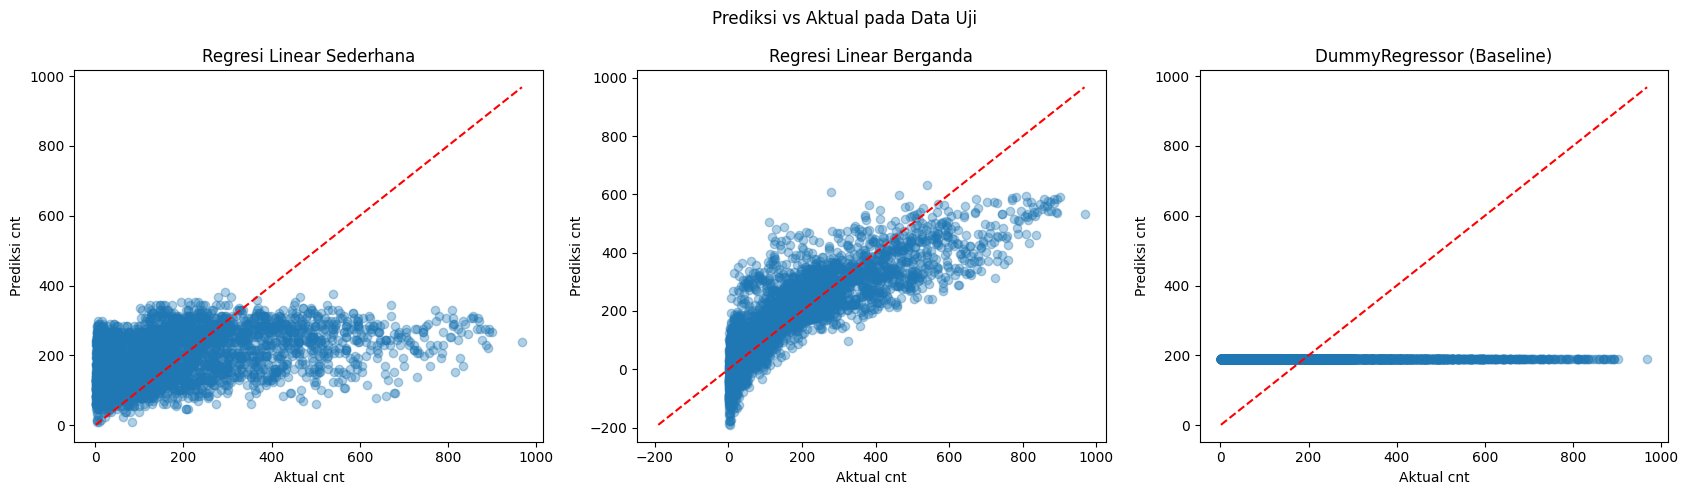

In [13]:
# Plot aktual vs prediksi untuk setiap model
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=.35)
    lim_min = min(y_test.min(), pred.min())
    lim_max = max(y_test.max(), pred.max())
    ax.plot([lim_min, lim_max], [lim_min, lim_max], "r--")
    ax.set_title(name)
    ax.set_xlabel("Aktual cnt")
    ax.set_ylabel("Prediksi cnt")
plt.suptitle("Prediksi vs Aktual pada Data Uji")
plt.tight_layout()
plt.show()

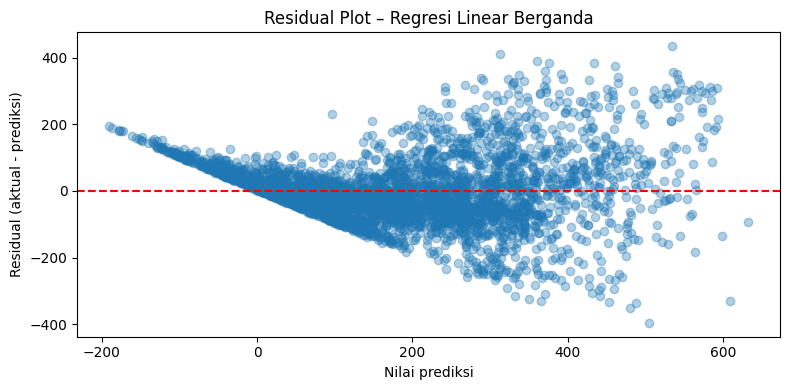

Model terbaik sementara berdasarkan RMSE test: Regresi Linear Berganda


In [14]:
# Plot residual untuk model terbaik berdasarkan RMSE data uji
best_name = evaluation.iloc[0]["Model"]
best_pred = predictions[best_name]
residuals = y_test.to_numpy() - best_pred
plt.figure(figsize=(8, 4))
plt.scatter(best_pred, residuals, alpha=.35)
plt.axhline(0, color="red", linestyle="--")
plt.title(f"Residual Plot – {best_name}")
plt.xlabel("Nilai prediksi")
plt.ylabel("Residual (aktual - prediksi)")
plt.tight_layout()
plt.show()
print("Model terbaik sementara berdasarkan RMSE test:", best_name)

In [15]:
# Interpretasi koefisien regresi berganda
multiple_fitted = fitted["Regresi Linear Berganda"]
feature_names = multiple_fitted.named_steps["preprocess"].get_feature_names_out()
coefficients = multiple_fitted.named_steps["regressor"].coef_
coef_table = pd.DataFrame({"Fitur hasil transformasi": feature_names, "Koefisien": coefficients})
coef_table["Abs Koefisien"] = coef_table["Koefisien"].abs()
display(coef_table.sort_values("Abs Koefisien", ascending=False).drop(columns="Abs Koefisien").head(20))
print("Intercept model:", multiple_fitted.named_steps["regressor"].intercept_)

,Fitur hasil transformasi,Koefisien
35,cat__hr_17,377.247443
36,cat__hr_18,345.080924
26,cat__hr_8,308.030295
37,cat__hr_19,236.281476
34,cat__hr_16,225.317315
30,cat__hr_12,173.734958
25,cat__hr_7,171.845761
31,cat__hr_13,169.211908
27,cat__hr_9,165.038885
33,cat__hr_15,157.631160


Intercept model: -23.865349573965972


### Cara membaca koefisien
Koefisien positif berarti kenaikan satu unit fitur hasil transformasi berkaitan dengan kenaikan prediksi `cnt`, dengan fitur lain dianggap tetap. Koefisien negatif berarti hubungan berlawanan. Untuk fitur numerik, satu unit setelah StandardScaler berarti satu standar deviasi. Untuk fitur kategori One-Hot, koefisien dibandingkan dengan kategori referensi yang dihilangkan (`drop='first'`). Koefisien menunjukkan asosiasi model, bukan hubungan sebab-akibat.

In [16]:
# Tabel perbandingan model dengan baseline dan indikasi overfitting
baseline_test_rmse = float(evaluation.loc[evaluation["Model"] == "DummyRegressor (Baseline)", "Test RMSE"].iloc[0])
best_row = evaluation.iloc[0]
gap = float(best_row["Test RMSE"] - best_row["Train RMSE"])
print(f"Model dengan RMSE test terendah: {best_row['Model']}")
print(f"Test MAE: {best_row['Test MAE']:.3f} sepeda/jam")
print(f"Test RMSE: {best_row['Test RMSE']:.3f} sepeda/jam")
print(f"Test R²: {best_row['Test R2']:.3f}")
print(f"Baseline test RMSE: {baseline_test_rmse:.3f}")
print(f"Selisih RMSE test-train model terpilih: {gap:.3f}")
if best_row["Test RMSE"] < baseline_test_rmse and best_row["Test R2"] > float(evaluation.loc[evaluation["Model"] == "DummyRegressor (Baseline)", "Test R2"].iloc[0]):
    print("Interpretasi baseline: model terpilih mengungguli DummyRegressor pada RMSE dan R² data uji.")
else:
    print("Interpretasi baseline: model terpilih belum mengungguli baseline pada kedua ukuran tersebut; manfaat prediktif perlu dipertanyakan.")
if gap > 0:
    print("Train-test: error test lebih besar daripada error train; ini wajar, tetapi selisih besar dapat mengindikasikan overfitting.")
else:
    print("Train-test: error test tidak lebih besar daripada error train; periksa kembali kestabilan pada CV dan data lain.")

Model dengan RMSE test terendah: Regresi Linear Berganda
Test MAE: 75.082 sepeda/jam
Test RMSE: 101.873 sepeda/jam
Test R²: 0.686
Baseline test RMSE: 181.790
Selisih RMSE test-train model terpilih: 0.339
Interpretasi baseline: model terpilih mengungguli DummyRegressor pada RMSE dan R² data uji.
Train-test: error test lebih besar daripada error train; ini wajar, tetapi selisih besar dapat mengindikasikan overfitting.


### Keputusan saya
Model dipilih berdasarkan RMSE data uji terendah, tetapi kelayakannya tetap dibandingkan dengan DummyRegressor. MAE ditafsirkan sebagai rata-rata besar kesalahan prediksi dalam satuan sepeda per jam. Selisih metrik train dan test digunakan sebagai indikasi overfitting; hasil CV membantu menilai kestabilan model.

## 6. Deployment / Kesimpulan dan Rekomendasi
Bagian berikut menghasilkan kesimpulan otomatis berdasarkan hasil aktual setelah semua sel dijalankan. Pastikan angka yang tampil sesuai output notebook sebelum dimasukkan ke laporan/presentasi.

In [20]:
# Keputusan akhir otomatis dengan angka aktual
ev = evaluation.set_index("Model")
chosen = evaluation.sort_values("Test RMSE").iloc[0]
base = ev.loc["DummyRegressor (Baseline)"]
chosen_name = chosen["Model"]
mae_gain = base["Test MAE"] - chosen["Test MAE"]
rmse_gain = base["Test RMSE"] - chosen["Test RMSE"]
r2_gain = chosen["Test R2"] - base["Test R2"]

print("="*72)
print("KEPUTUSAN AKHIR")
print("="*72)
print(f"Model dengan RMSE test terendah adalah {chosen_name}.")
print(f"Alasan 1: MAE model terpilih = {chosen['Test MAE']:.2f} sepeda/jam, dibanding baseline = {base['Test MAE']:.2f}.")
print(f"Alasan 2: RMSE model terpilih = {chosen['Test RMSE']:.2f} sepeda/jam, dibanding baseline = {base['Test RMSE']:.2f}.")
print(f"Alasan 3: R² model terpilih = {chosen['Test R2']:.3f}, dibanding baseline = {base['Test R2']:.3f}.")

if rmse_gain > 0 and mae_gain > 0 and r2_gain > 0:
    print("KESIMPULAN KELAYAKAN: Model terpilih lebih baik daripada baseline pada MAE, RMSE, dan R² data uji. Model layak dipertimbangkan sebagai alat bantu perencanaan awal, tetapi belum boleh dianggap pengganti evaluasi operasional.")
else:
    print("KESIMPULAN KELAYAKAN: Model terpilih belum menunjukkan keunggulan konsisten atas baseline. Belum cukup bukti untuk merekomendasikannya sebagai model operasional.")

print("KETERBATASAN:")
print("- Data hanya mencakup Capital Bikeshare di Washington D.C. pada 2011–2012 sehingga pola saat ini/lokasi lain dapat berbeda.")
print("- Model linear mungkin tidak menangkap pola non-linear dan interaksi kompleks antara waktu, cuaca, dan permintaan.")
print("- Faktor eksternal seperti acara khusus, gangguan layanan, perubahan tarif, dan ketersediaan sepeda tidak seluruhnya tercakup.")
print("- MAE/RMSE dihitung pada data uji dari pembagian acak; evaluasi berbasis waktu (time-based split) dapat lebih realistis untuk prediksi masa depan.")

print("SARAN PERBAIKAN:")
print("- Uji validasi berbasis waktu agar evaluasi meniru penggunaan untuk periode mendatang.")
print("- Tambahkan data terbaru, kalender acara, hari libur khusus, dan informasi ketersediaan stasiun.")
print("- Bandingkan dengan model non-linear seperti Random Forest atau Gradient Boosting sebagai pengembangan lanjutan.")
print("- Pantau error secara berkala dan latih ulang model ketika pola permintaan berubah.")

KEPUTUSAN AKHIR
Model dengan RMSE test terendah adalah Regresi Linear Berganda.
Alasan 1: MAE model terpilih = 75.08 sepeda/jam, dibanding baseline = 143.02.
Alasan 2: RMSE model terpilih = 101.87 sepeda/jam, dibanding baseline = 181.79.
Alasan 3: R² model terpilih = 0.686, dibanding baseline = -0.000.
KESIMPULAN KELAYAKAN: Model terpilih lebih baik daripada baseline pada MAE, RMSE, dan R² data uji. Model layak dipertimbangkan sebagai alat bantu perencanaan awal, tetapi belum boleh dianggap pengganti evaluasi operasional.
KETERBATASAN:
- Data hanya mencakup Capital Bikeshare di Washington D.C. pada 2011–2012 sehingga pola saat ini/lokasi lain dapat berbeda.
- Model linear mungkin tidak menangkap pola non-linear dan interaksi kompleks antara waktu, cuaca, dan permintaan.
- Faktor eksternal seperti acara khusus, gangguan layanan, perubahan tarif, dan ketersediaan sepeda tidak seluruhnya tercakup.
- MAE/RMSE dihitung pada data uji dari pembagian acak; evaluasi berbasis waktu (time-based s

### Rekomendasi penggunaan
Pengelola dapat memakai hasil prediksi sebagai estimasi awal kebutuhan sepeda per jam. Untuk operasional, sebaiknya tambahkan buffer keselamatan dan evaluasi prediksi secara berkala, terutama pada jam puncak dan saat cuaca ekstrem. Jangan menerapkan model secara penuh apabila hasilnya belum mengungguli baseline.